# MECHA in metafspm, 2: a soil drier on one side of the root

MECHA's *plant problem* takes the soil's water potential per Compartment (`soil_psi`, an input of role `Soil`):
a soil model gives each border wall and junction the potential of the soil it touches. Here, a soil wet on one side
of a root section and dry on the other (near a drying surface, a stone, a neighbour's depletion zone), and what it
changes: where the water enters, whether some leaves the root on the dry side, and the barriers' role.

> **Developer tutorial 2** of seven:
> | | notebook | what it covers |
> |---|---|---|
> | 0 | `00_overview.ipynb` | the package's modules, the original MECHA and its reactions branch, how the port is validated, the docs |
> | 1 | `01_granap_mecha.ipynb` | GRANAP's anatomies and MECHA's hydraulics coupled in a plant model; MECHA's inputs by role; scenarios; the barriers |
> | 2 | `02_soil_gradient.ipynb` | the plant problem with a soil drier on one side of a root section |
> | 3 | `03_needle_solutes.ipynb` | a pine needle of three sections, its transpiration, MechaSolutes over a day |
> | 4 | `04_full_plant.ipynb` | a whole seedling in its soil, run to the fixed point |
> | 5 | `05_extend_the_component.ipynb` | add a variable and a process to the component, run and test it |
> | 6 | `06_solute_storage_and_decay.ipynb` | the solutes' storage fractions, their first-order loss and the liquid boundary |
>
> New to MECHA? Start with the user tutorials (`../user/01_first_run.ipynb`): they solve a root section and explain
> its results without the framework's details.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from openalea.metafspm.coupling.composite_wrapper import CompositeModel
from openalea.metafspm.coupling.translator import Translator
from openalea.metafspm.scene.scene import Scene

from openalea.granap.metafspm.architectures import RootAxis
from openalea.granap.metafspm.component import GranapAnatomy, junction_rules
from openalea.mecha import plots
from openalea.mecha.component import MechaHydraulics


class RootHydraulics(CompositeModel):                  # the first tutorial's plant model
    initiators = (RootAxis, GranapAnatomy)
    from_scale, nodes, wiring = "SubOrgan", "Compartment", junction_rules

    def __init__(self, data_structure, time_step):
        self.anatomy = GranapAnatomy(data_structure=data_structure, time_step=time_step)
        self.hydraulics = MechaHydraulics(data_structure=data_structure, time_step=time_step)
        self.declare_data_and_couple_components(translator_path=Translator(),
                                                components=(self.anatomy, self.hydraulics))

    def run(self):
        self.anatomy()
        self.hydraulics()

One plant. Its scenario sets the collar (the section's xylem) at −5000 hPa and skips the standard problem; a
suberized endodermis (barrier 3), as a development model would give it.

In [2]:
COLLAR = -5000.
scenario = {"collar_condition": 1., "collar_psi": COLLAR, "standard_solve": 0.}
scene = Scene(pd.DataFrame([dict(plant="root", model=RootHydraulics, x=0., y=0., z=0., rotation=0.,
                                 scenario={"parameters": scenario})]))
ds = scene.populations[0].data_structure
mecha = scene.populations[0].instance.hydraulics
segment = int(ds.entity_ids("SubOrgan")[0])
ds.set("barrier", np.full(ds.n_nodes(), 3.))
scene.run()

The nodes in contact with the soil are those with a soil conductance (the epidermis' outer walls and junctions);
their angle around the section gives the gradient its direction. The soil potential varies as a cosine of it, from
−100 hPa (θ = 0, right) to −8000 hPa (θ = π, left): drier than the xylem on the left.

In [3]:
border = ds.get("soil_conductance") > 0
x, y = ds.get("section_x"), ds.get("section_y")
angle = np.arctan2(y - y[border].mean(), x - x[border].mean())


def soil(wet, dry):
    return np.where(border, (wet + dry) / 2 + (wet - dry) / 2 * np.cos(angle), 0.)


def solve(soil_psi):
    """The soil model's role: give soil_psi; then one step. Returns the uptake per node (+ into the root)."""
    ds.set("soil_psi", soil_psi)
    scene.run()
    return ds.get("root_uptake").copy()


gradient = solve(soil(-100., -8000.))
gradient_frame = plots.port_frame(mecha, segment, psi="psi", flow="flow")
uniform = solve(np.where(border, soil(-100., -8000.)[border].mean(), 0.))       # the same mean, everywhere
uniform_frame = plots.port_frame(mecha, segment, psi="psi", flow="flow")
pd.DataFrame({name: {"net uptake": u.sum(), "entering": u[u > 0].sum(), "leaving": max(0., -u[u < 0].sum())}
              for name, u in (("gradient", gradient), ("uniform, same mean", uniform))}).T

,net uptake,entering,leaving
gradient,0.000194,0.002520,0.002327
"uniform, same mean",0.000195,0.000195,0.000000


The net uptake is the same: the mean soil potential sets it. But with the gradient, water enters on the wet side
and most of it leaves again on the dry side: the root redistributes water from wet to dry soil.

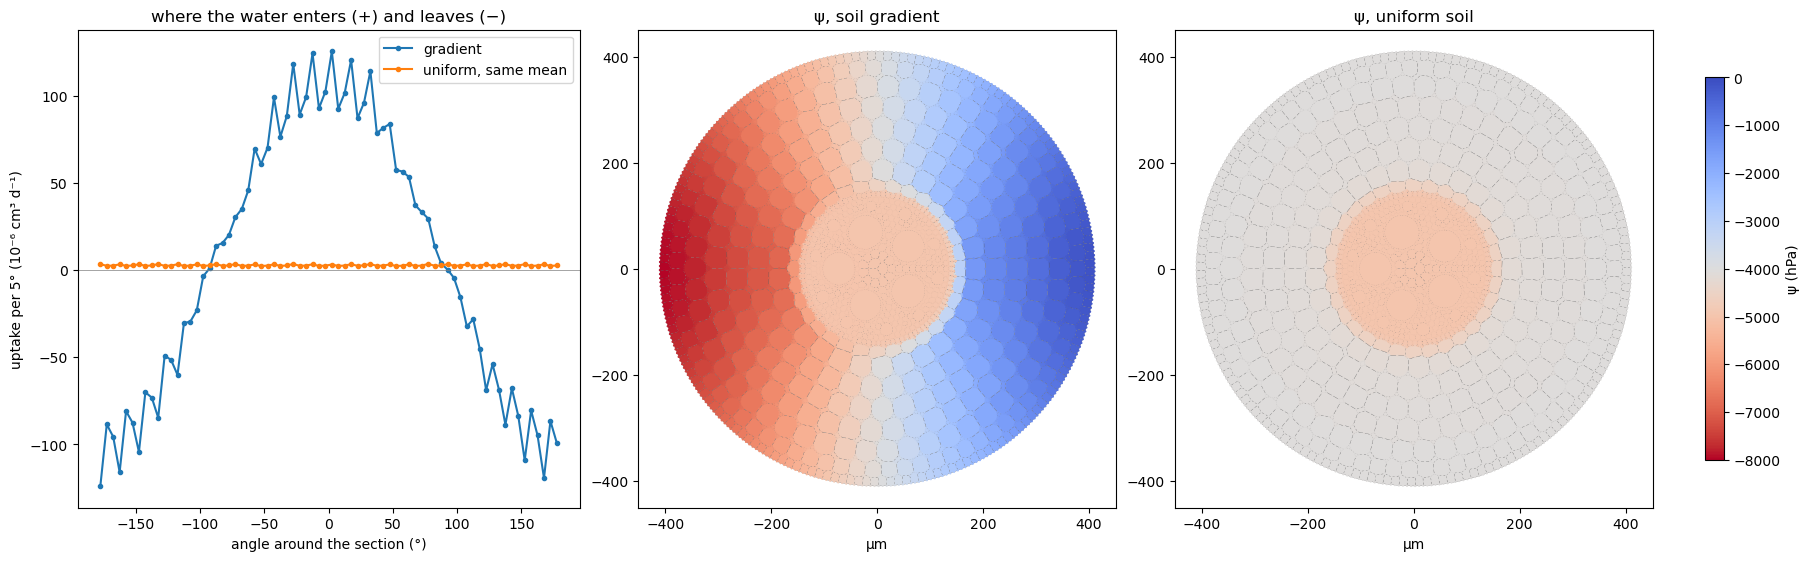

In [4]:
sectors = np.radians(np.arange(-180., 181., 5.))
which = np.digitize(angle[border], sectors) - 1
middle = np.degrees(sectors[:-1] + sectors[1:]) / 2
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), layout="constrained")
for u, label in ((gradient, "gradient"), (uniform, "uniform, same mean")):
    axes[0].plot(middle, np.bincount(which, u[border], minlength=middle.size)[:middle.size] * 1e6, "o-", ms=3,
                 label=label)
axes[0].axhline(0., color="0.5", lw=0.5)
axes[0].set(xlabel="angle around the section (°)", ylabel="uptake per 5° (10⁻⁶ cm³ d⁻¹)",
            title="where the water enters (+) and leaves (−)")
axes[0].legend()
norm = plt.Normalize(-8000., 0.)
points = plots.psi_map(axes[1], gradient_frame, title="ψ, soil gradient", norm=norm)
plots.psi_map(axes[2], uniform_frame, title="ψ, uniform soil", norm=norm)
fig.colorbar(points, ax=axes[1:], label="ψ (hPa)", shrink=0.8)
plt.show()

The walls carry the water *around* the root, from the wet side to the dry, through the epidermis and the cortex:
with a suberized endodermis, little of it goes through the stele.

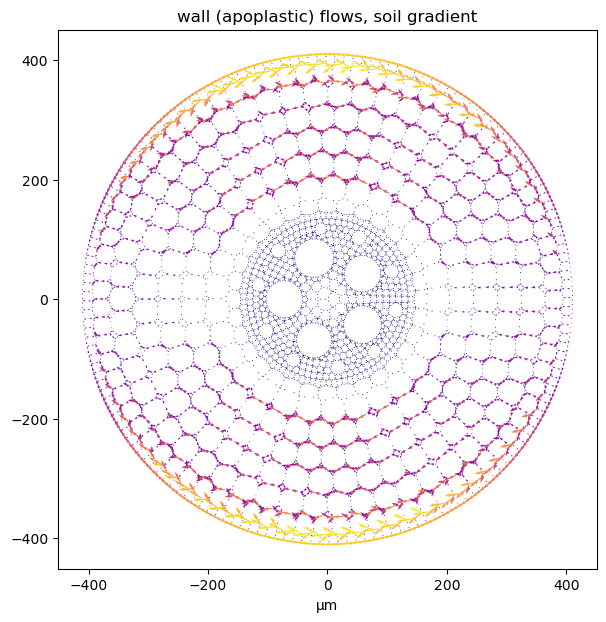

In [5]:
fig, ax = plt.subplots(figsize=(7, 7))
plots.flow_vectors(ax, gradient_frame, path="wall", title="wall (apoplastic) flows, soil gradient")
plt.show()

## How much is redistributed: the dry side's potential and the barriers

The share of the entering water that leaves on the dry side, for an endodermal Casparian strip (barrier 1) and a
suberized endodermis (barrier 3). The net uptake reverses when the soil's mean potential reaches the collar's
(dotted). The suberized endodermis lowers the net uptake, but redistributes a larger share of what enters.

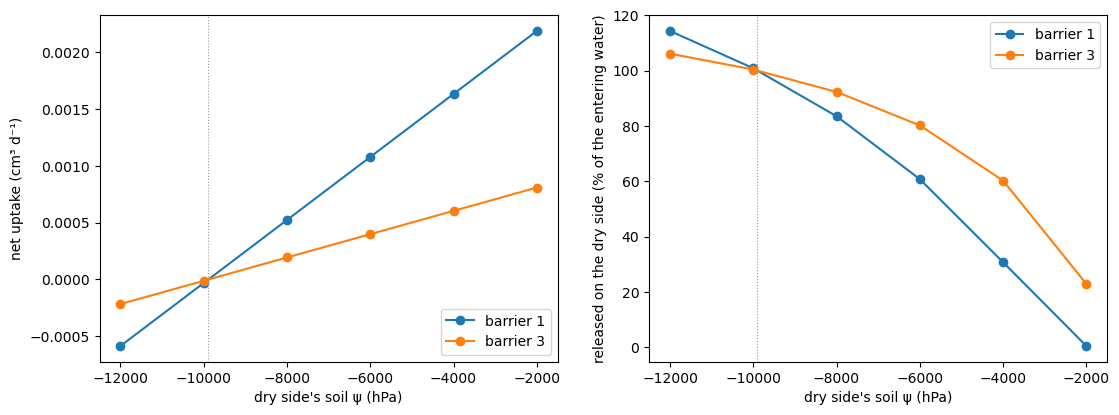

In [6]:
rows = []
for barrier in (1., 3.):
    ds.set("barrier", np.full(ds.n_nodes(), barrier))
    for dry in (-2000., -4000., -6000., -8000., -10000., -12000.):
        u = solve(soil(-100., dry))
        rows.append(dict(barrier=int(barrier), dry=dry, net=u.sum(), released=-u[u < 0].sum() / u[u > 0].sum()))
table = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for barrier, rows_b in table.groupby("barrier"):
    axes[0].plot(rows_b["dry"], rows_b["net"], "o-", label=f"barrier {barrier}")
    axes[1].plot(rows_b["dry"], 100 * rows_b["released"], "o-", label=f"barrier {barrier}")
axes[0].set(xlabel="dry side's soil ψ (hPa)", ylabel="net uptake (cm³ d⁻¹)")
axes[1].set(xlabel="dry side's soil ψ (hPa)", ylabel="released on the dry side (% of the entering water)")
for ax in axes:
    ax.axvline(2 * COLLAR + 100., color="0.6", lw=0.8, ls=":")
    ax.legend()
plt.show()

## Part of the root out of contact with the soil

Roots often touch the soil on one side only: a gap, a macropore, a stone. MECHA's `x_contact` keeps in contact only
the border walls and junctions at x ≥ `x_contact` (µm, in the section's coordinates): here, the right half. The
plasmodesmata's aperture can also depend on the distance to the wetted surface (`pd_spatial_profile`, from
`develop`): 1 at the nearest plasmodesmata, 0.6 at the farthest, linearly (profile 1). The distance is measured
along the section's graph of walls, junctions and cells, from the nodes in contact (`contact_distance`).

In [7]:
ds.set("barrier", np.full(ds.n_nodes(), 1.))
centre_x = float(mecha.section_geometries()[segment][2].gravity_center[0])
mecha.x_contact = centre_x                             # the right half in contact
mecha.pd_spatial_profile = 1.                          # the plasmodesmata's aperture by distance (linear)
half = solve(np.where(border, -100., 0.))
half_frame = plots.port_frame(mecha, segment, psi="psi", flow="flow")
in_contact = ds.get("soil_conductance") > 0
print(f"{in_contact.sum()} of {border.sum()} border nodes in contact; net uptake {half.sum():.3g} cm³ d⁻¹")

168 of 336 border nodes in contact; net uptake 0.0023 cm³ d⁻¹


The distance to the wetted surface, and the plasmodesmata's aperture it gives (the cells next to the wetted
surface circled):

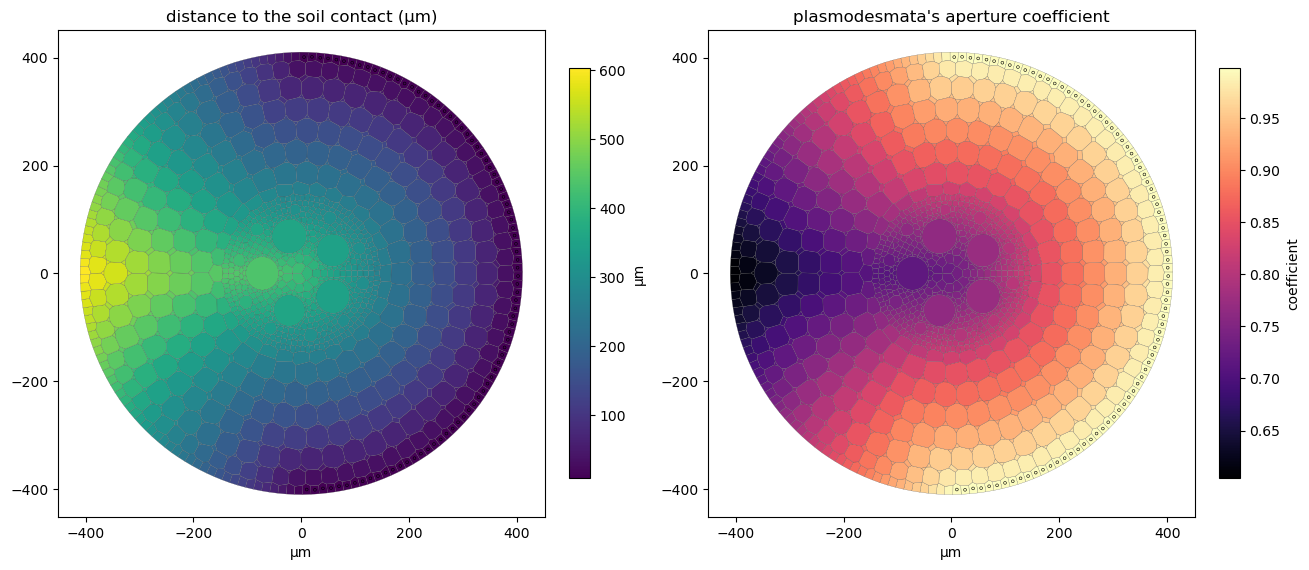

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6), layout="constrained")
distance, aperture = plots.contact_distance_map(axes, half_frame)
fig.colorbar(distance, ax=axes[0], label="µm", shrink=0.7)
fig.colorbar(aperture, ax=axes[1], label="coefficient", shrink=0.7)
plt.show()

Along the wet→dry transect (negative on the wet side, through the centre; `axis="signed"`), the potential and
the pathways of the radial flow, each cell layer's wet and dry halves apart. The potential falls from about −100 hPa
at the wetted surface to about −3800 hPa in the stele; on the dry side, out of contact, the cells stay near −1600 hPa.
On both halves the walls carry most of the radial flow.

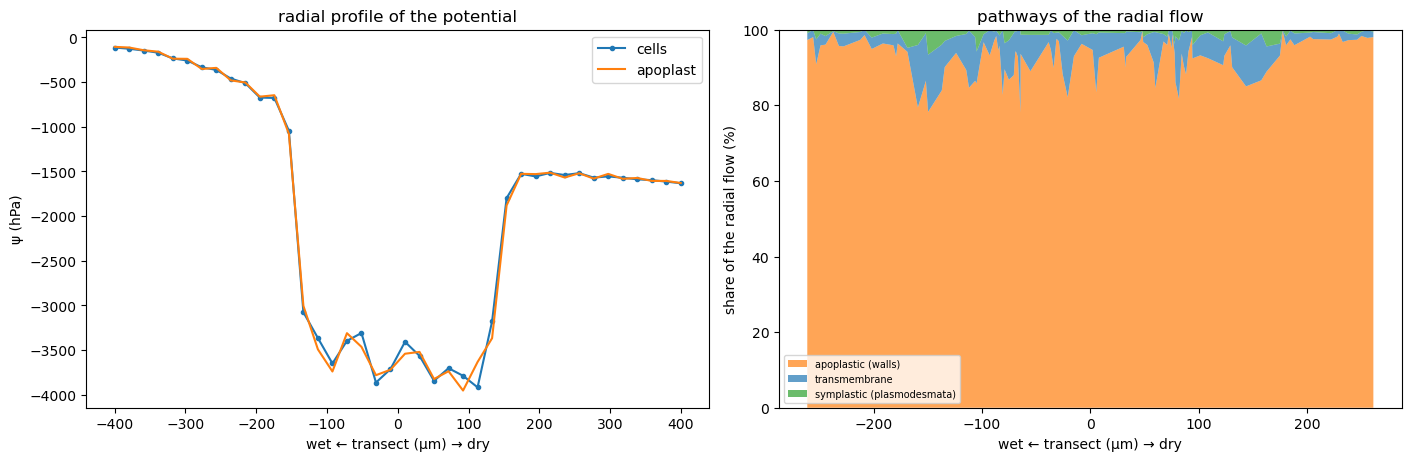

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), layout="constrained")
plots.radial_profile(axes[0], half_frame, axis="signed")
axes[0].legend()
plots.pathway_breakdown(axes[1], half_frame, axis="signed")
plt.show()
mecha.x_contact, mecha.pd_spatial_profile = -15E9, 0.     # back to the defaults

Next: `03_needle_solutes.ipynb`, an organ of several sections, its transpiration and its sugars.